# 01 · Exploratory Data Analysis (EDA)

**Project:** Predicting the **Remaining Useful Life (RUL)** of aircraft engines — NASA C-MAPSS, subset **FD001**.

**RUL** = how many more cycles (flights) an engine can run before it fails.
It is a number, so this is a **regression** problem.

**In this notebook we only *look* at the data** (no models yet):
1. Load the data and check its quality
2. How long do engines live?
3. Which sensors are useless (never change)?
4. How do sensors behave as the engine gets close to failure?
5. Which sensors are most related to RUL?

> 💡 Cells marked with **⋯** are hidden because they only contain plotting or helper code. Click them to expand.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from utils import savefig

## 1. Load the data

The NASA files are plain text with **26 columns** and no header:

| Column | Meaning |
|---|---|
| `unit` | engine ID (1 to 100) |
| `cycle` | time step — one cycle ≈ one flight |
| `setting_1..3` | operating settings (altitude, speed, throttle) |
| `s1..s21` | 21 sensor readings |

* **train_FD001.txt** → 100 engines, recorded **until they fail**.
* **test_FD001.txt** → 100 other engines, recording **stops before failure**.
* **RUL_FD001.txt** → the true RUL of each test engine (the answer key).

In [2]:
# The NASA files are plain text: values separated by spaces, no header row.
# So we tell pandas the separator (sep=r"\s+" = one or more spaces) and give the 26 column names ourselves.
columns = ["unit", "cycle", "setting_1", "setting_2", "setting_3"] + [f"s{i}" for i in range(1, 22)]

train = pd.read_csv("../data/raw/train_FD001.txt", sep=r"\s+", header=None, names=columns)
test = pd.read_csv("../data/raw/test_FD001.txt", sep=r"\s+", header=None, names=columns)

print("Train:", train.shape, "→", train["unit"].nunique(), "engines")
print("Test :", test.shape, "→", test["unit"].nunique(), "engines")
print("Missing values:", train.isna().sum().sum(), "| Duplicate rows:", train.duplicated().sum())
train.head()

Train: (20631, 26) → 100 engines
Test : (13096, 26) → 100 engines
Missing values: 0 | Duplicate rows: 0


,unit,cycle,setting_1,setting_2,setting_3,s1,s2,s3,s4,s5,...,s12,s13,s14,s15,s16,s17,s18,s19,s20,s21
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044


**What the sensors measure** (from the NASA documentation):

| Sensor | Meaning | Sensor | Meaning |
|---|---|---|---|
| s1 | Fan inlet temperature | s12 | Fuel flow / Ps30 ratio |
| s2 | LPC outlet temperature | s13 | Corrected fan speed |
| s3 | HPC outlet temperature | s14 | Corrected core speed |
| s4 | LPT outlet temperature | s15 | Bypass ratio |
| s5 | Fan inlet pressure | s16 | Burner fuel-air ratio |
| s6 | Bypass-duct pressure | s17 | Bleed enthalpy |
| s7 | HPC outlet pressure | s18 | Demanded fan speed |
| s8 | Physical fan speed | s19 | Demanded corrected fan speed |
| s9 | Physical core speed | s20 | HPT coolant bleed |
| s10 | Engine pressure ratio | s21 | LPT coolant bleed |
| s11 | HPC outlet static pressure (Ps30) | | |

*(LPC/HPC = low/high pressure compressor, LPT/HPT = low/high pressure turbine.)*

✅ **Data quality:** no missing values and no duplicate rows, so no cleaning is needed.

## 2. How long do engines live?

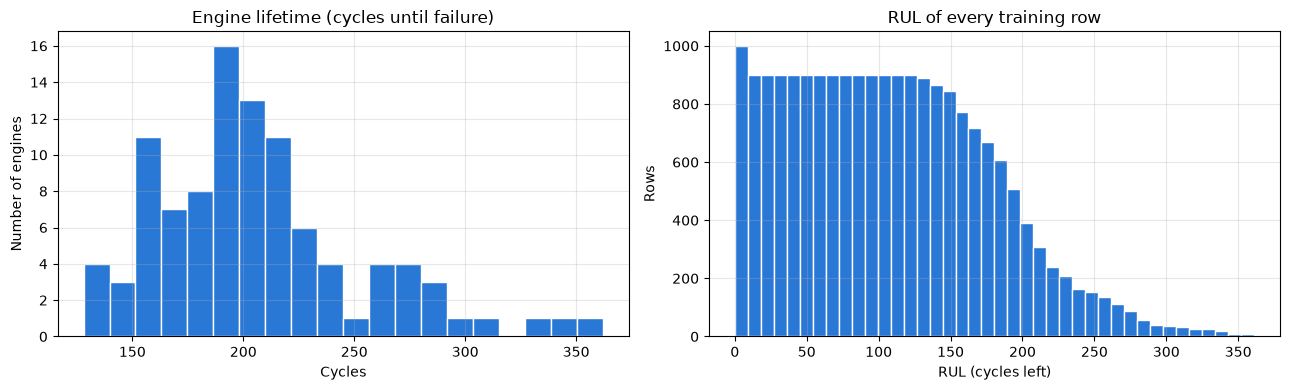

count    100.0
mean     206.0
std       46.0
min      128.0
25%      177.0
50%      199.0
75%      229.0
max      362.0
Name: cycle, dtype: float64


In [3]:
life = train.groupby("unit")["cycle"].max()
rul = train.groupby("unit")["cycle"].transform("max") - train["cycle"]

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].hist(life, bins=20, color="#2a78d6", edgecolor="white")
ax[0].set(title="Engine lifetime (cycles until failure)", xlabel="Cycles", ylabel="Number of engines")
ax[1].hist(rul, bins=40, color="#2a78d6", edgecolor="white")
ax[1].set(title="RUL of every training row", xlabel="RUL (cycles left)", ylabel="Rows")
savefig("01_engine_lifetime")
print(life.describe().round(0))

**Observation:**
* Engines live between **128 and 362 cycles** (average ≈ 206). Every engine is different.
* Small RUL values appear for every engine, but large RUL values (> 200) come only from a few long-lived engines.

## 3. Which sensors are useless? (Variance Threshold)
A sensor that (almost) never changes has **≈ 0 variance** and carries **no information**. This is the *Variance Threshold*
filter method of feature selection: we check the spread (std) and the number of different values of each sensor.

In [4]:
sensors = [f"s{i}" for i in range(1, 22)]
summary = pd.DataFrame({"std": train[sensors].std().round(4),
                        "unique_values": train[sensors].nunique()})
summary["useless"] = summary["unique_values"] <= 2
print("Useless sensors:", summary.index[summary["useless"]].tolist())
summary.T

Useless sensors: ['s1', 's5', 's6', 's10', 's16', 's18', 's19']


,s1,s2,s3,s4,s5,s6,s7,s8,s9,s10,...,s12,s13,s14,s15,s16,s17,s18,s19,s20,s21
std,0.0,0.5001,6.1311,9.0006,0.0,0.0014,0.8851,0.071,22.0829,0.0,...,0.7376,0.0719,19.0762,0.0375,0.0,1.5488,0.0,0.0,0.1807,0.1083
unique_values,1,310,3012,4051,1,2,513,53,6403,1,...,427,56,6078,1918,1,13,1,1,120,4745
useless,True,False,False,False,True,True,False,False,False,True,...,False,False,False,False,True,False,True,True,False,False


In [5]:
print("Unique values of each operating setting:")
print(train[["setting_1", "setting_2", "setting_3"]].nunique())
print("setting_3 is always:", train["setting_3"].unique())

Unique values of each operating setting:
setting_1    158
setting_2     13
setting_3      1
dtype: int64
setting_3 is always: [100.]


**Observation:**
* **7 sensors are useless** (s1, s5, s6, s10, s16, s18, s19) → they will be **removed**. **14 sensors remain.**
* FD001 has **only one operating condition** (setting_3 is always 100, settings 1–2 are just tiny noise),
  so the settings are also dropped and no "operating-condition normalisation" is needed.

## 4. How do sensors change as an engine gets close to failure?
Each line is one engine. The x-axis is **RUL**, so **failure is at 0** (right side).

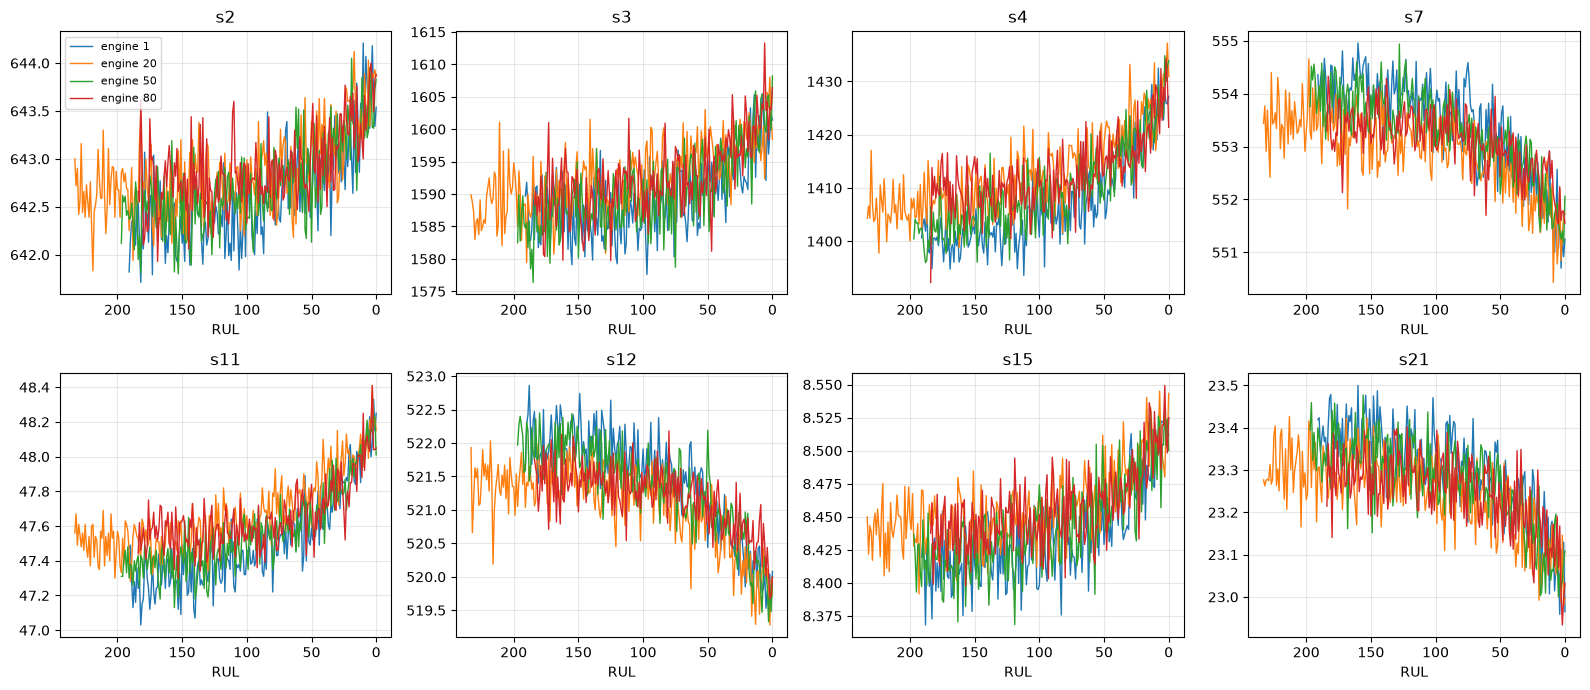

In [6]:
plot_sensors = ["s2", "s3", "s4", "s7", "s11", "s12", "s15", "s21"]
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, s in zip(axes.flat, plot_sensors):
    for unit in [1, 20, 50, 80]:
        d = train[train["unit"] == unit]
        ax.plot(d["cycle"].max() - d["cycle"], d[s], lw=1, label=f"engine {unit}")
    ax.set(title=s, xlabel="RUL")
    ax.invert_xaxis()
axes[0, 0].legend(fontsize=8)
savefig("01_sensor_trends")

**Observation:**
* Sensors are **noisy**, but close to failure they clearly **drift**.
* s2, s3, s4, s11, s15 go **up** ⬆ and s7, s12, s21 go **down** ⬇ as the engine wears out.
* Far from failure the lines are almost flat → a healthy engine looks the same at RUL 300 and RUL 150.

## 5. Which sensors are most related to RUL? (Pearson correlation)

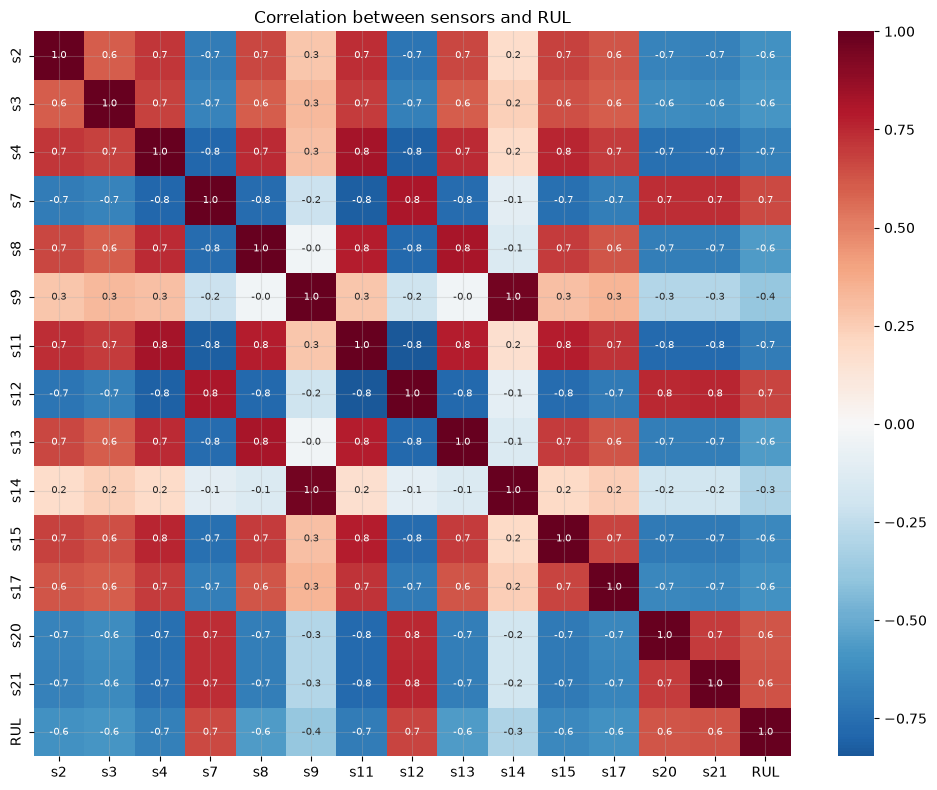

In [7]:
useful = summary.index[~summary["useless"]].tolist()
corr = train[useful].assign(RUL=rul).corr()
plt.figure(figsize=(10, 8))
sns.heatmap(corr, cmap="RdBu_r", center=0, annot=True, fmt=".1f", annot_kws={"size": 7})
plt.title("Correlation between sensors and RUL")
savefig("01_correlation")

In [8]:
corr["RUL"].drop("RUL").sort_values().round(2).to_frame("correlation with RUL")

,correlation with RUL
s11,-0.70
s4,-0.68
s15,-0.64
s2,-0.61
s17,-0.61
s3,-0.58
s8,-0.56
s13,-0.56
s9,-0.39
s14,-0.31


**Observation:**
* **s11, s4, s12, s7, s15, s21, s20** are most related to RUL (|correlation| ≈ 0.6–0.7).
* Many sensors are also correlated **with each other** (multicollinearity), because they all react to the same wear.
  This can make Linear Regression weights unstable.

## 6. Early life vs late life

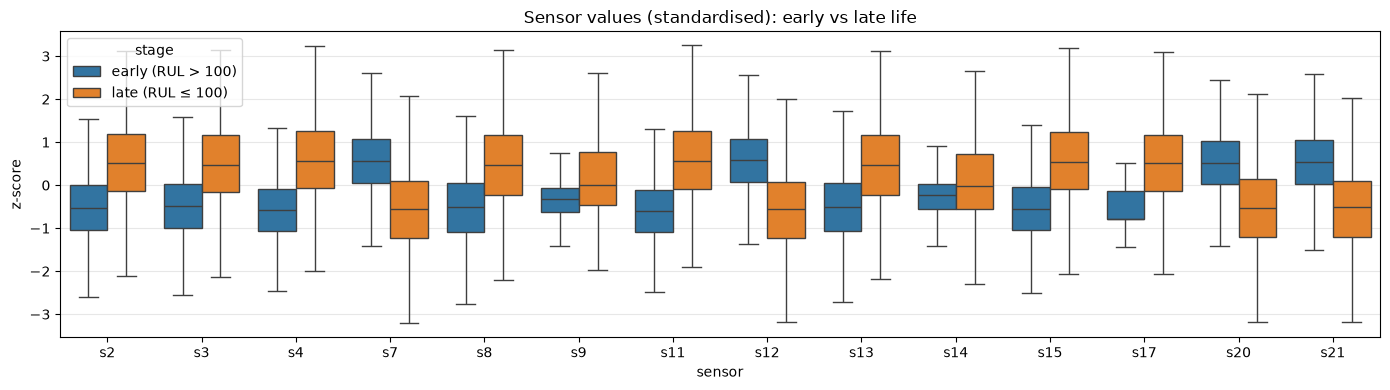

In [9]:
stage = np.where(rul > 100, "early (RUL > 100)", "late (RUL ≤ 100)")
z = (train[useful] - train[useful].mean()) / train[useful].std()   # put all sensors on the same scale
z["stage"] = stage
plt.figure(figsize=(14, 4))
sns.boxplot(data=z.melt(id_vars="stage"), x="variable", y="value", hue="stage", showfliers=False)
plt.title("Sensor values (standardised): early vs late life")
plt.xlabel("sensor"); plt.ylabel("z-score")
savefig("01_early_vs_late")

**Observation:** late-life values are shifted, but the boxes **overlap**. One single reading is not enough to know the
RUL → we should look at the **trend over several cycles**. This is why we build *rolling features* in notebook 02.

## ✅ Summary of EDA

| Finding | What we do next (notebook 02) |
|---|---|
| No missing / duplicate data | No cleaning needed |
| 7 sensors never change | Drop them → keep 14 sensors |
| Only one operating condition | Drop the 3 settings |
| Sensors drift near failure, but are noisy | Build moving-average / trend / deviation features |
| Healthy engines all look the same | Cap the RUL target at 125 |
| Every engine has a different lifetime | Split train/validation **by engine** |